In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
np.random.seed(42)
dates = pd.date_range(start="2023-01-01", periods=365, freq="D")
temp = np.random.uniform(-15, 30, size=365)
humidity = np.random.uniform(30, 95, size=365)
wind_speed = np.random.uniform(0.5, 8.0, size=365)
pm25 = (
    120
    - (temp * 1.5)
    + (humidity * 0.5)
    - (wind_speed * 10)
    + np.random.normal(0, 15, size=365)
)
pm25 = np.clip(pm25, 5, 300)
df = pd.DataFrame({
    'Date': dates,
    'Temperature_C': np.round(temp, 1),
    'Humidity_Pct': np.round(humidity, 1),
    'WindSpeed_m_s': np.round(wind_speed, 1),
    'PM25_mcg_m3': np.round(pm25, 1)
})
print("=== ПЕРВЫЕ 5 СТРОК ДАТАСЕТА ===")
print(df.head())

=== ПЕРВЫЕ 5 СТРОК ДАТАСЕТА ===
        Date  Temperature_C  Humidity_Pct  WindSpeed_m_s  PM25_mcg_m3
0 2023-01-01            1.9          55.1            1.7        119.7
1 2023-01-02           27.8          92.5            6.6         49.5
2 2023-01-03           17.9          88.8            5.5         91.0
3 2023-01-04           11.9          42.7            4.4         69.9
4 2023-01-05           -8.0          34.5            3.2        109.9


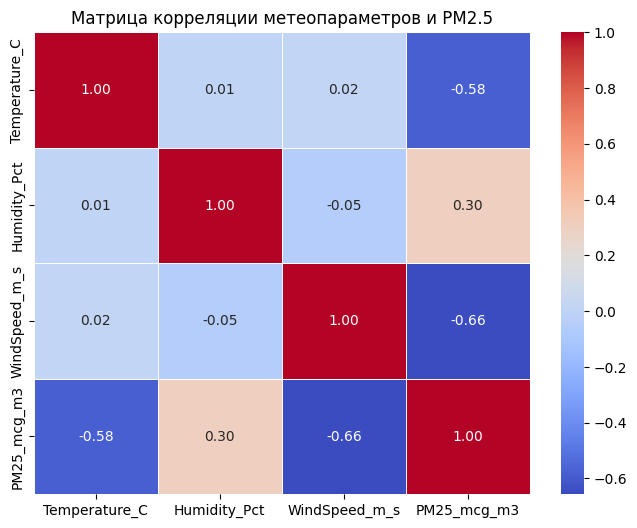

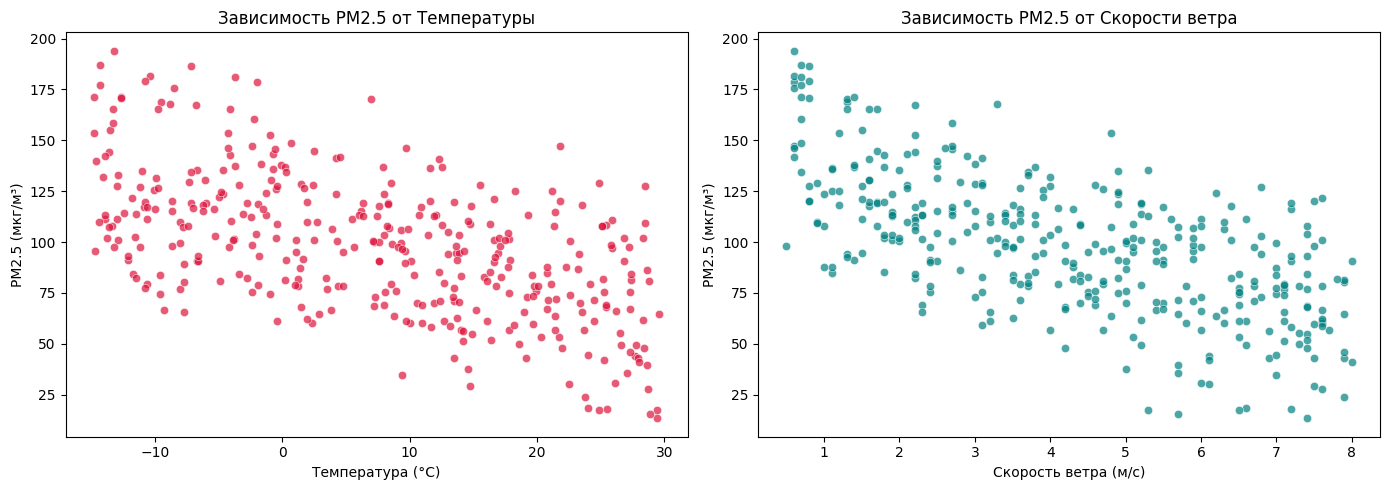

In [2]:
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляции метеопараметров и PM2.5')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(ax=axes[0], data=df, x='Temperature_C', y='PM25_mcg_m3', color='crimson', alpha=0.7)
axes[0].set_title('Зависимость PM2.5 от Температуры')
axes[0].set_xlabel('Температура (°C)')
axes[0].set_ylabel('PM2.5 (мкг/м³)')
sns.scatterplot(ax=axes[1], data=df, x='WindSpeed_m_s', y='PM25_mcg_m3', color='teal', alpha=0.7)
axes[1].set_title('Зависимость PM2.5 от Скорости ветра')
axes[1].set_xlabel('Скорость ветра (м/с)')
axes[1].set_ylabel('PM2.5 (мкг/м³)')
plt.tight_layout()
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
X = df[['Temperature_C', 'Humidity_Pct', 'WindSpeed_m_s']]
y = df['PM25_mcg_m3']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
rf_r2 = r2_score(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
lr_r2 = r2_score(y_test, lr_preds)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))
print("=== СРАВНЕНИЕ МОДЕЛЕЙ ===")
print(f"Random Forest  -> R2 Score: {rf_r2:.3f} | RMSE: {rf_rmse:.2f}")
print(f"Linear Regression -> R2 Score: {lr_r2:.3f} | RMSE: {lr_rmse:.2f}")

=== СРАВНЕНИЕ МОДЕЛЕЙ ===
Random Forest  -> R2 Score: 0.817 | RMSE: 15.14
Linear Regression -> R2 Score: 0.858 | RMSE: 13.29


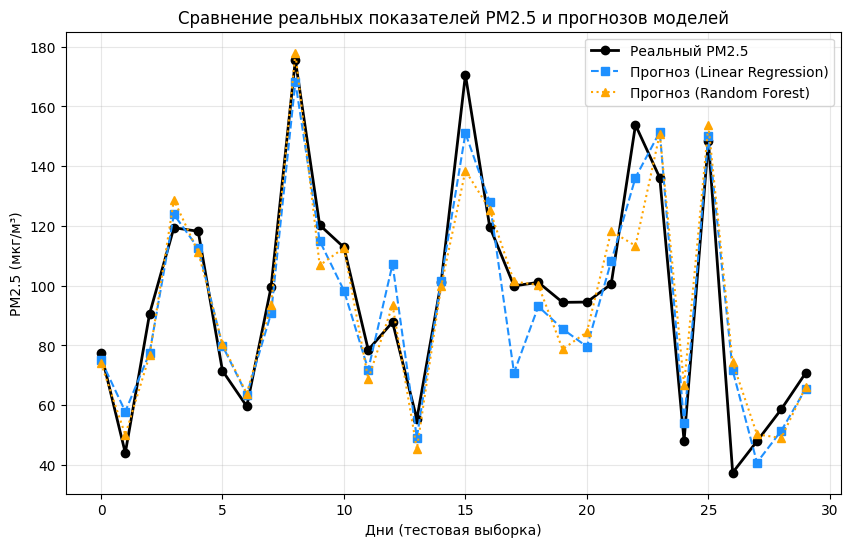

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(y_test.values[:30], label='Реальный PM2.5', color='black', marker='o', linewidth=2)
plt.plot(lr_preds[:30], label='Прогноз (Linear Regression)', color='dodgerblue', linestyle='--', marker='s')
plt.plot(rf_preds[:30], label='Прогноз (Random Forest)', color='orange', linestyle=':', marker='^')
plt.title('Сравнение реальных показателей PM2.5 и прогнозов моделей')
plt.xlabel('Дни (тестовая выборка)')
plt.ylabel('PM2.5 (мкг/м³)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()